<div>
<img src="img/logo-seaborn.png" width="500"/>
</div>

# Seaborn — Visualisation statistique avec de nouveaux exemples

## I. Introduction

Seaborn est une bibliothèque de visualisation construite au-dessus de Matplotlib.
Elle facilite notamment les graphiques statistiques, l'utilisation directe des colonnes d'un DataFrame
et la comparaison de plusieurs groupes.

Le fil rouge de ce TP est un jeu de données synthétique sur la **mobilité urbaine** :
trajets à vélo, à pied ou en trottinette.

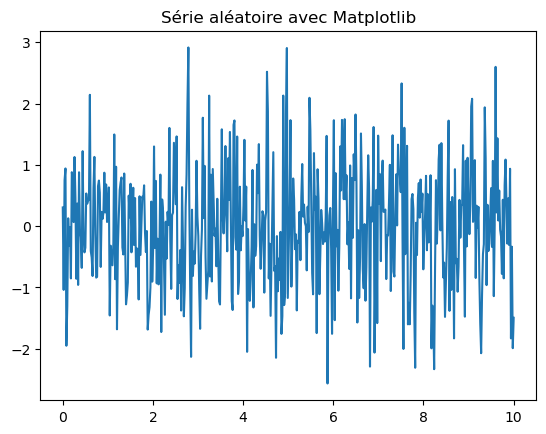

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

x = np.linspace(0, 10, 500)
y = rng.normal(size=500)

plt.plot(x, y)
plt.title("Série aléatoire avec Matplotlib")
plt.show()

Seaborn fournit des fonctions adaptées à l'analyse statistique.
Par exemple, `histplot` permet d'afficher un histogramme et, avec `kde=True`,
une estimation lissée de la distribution.

### Histogramme avec estimation KDE

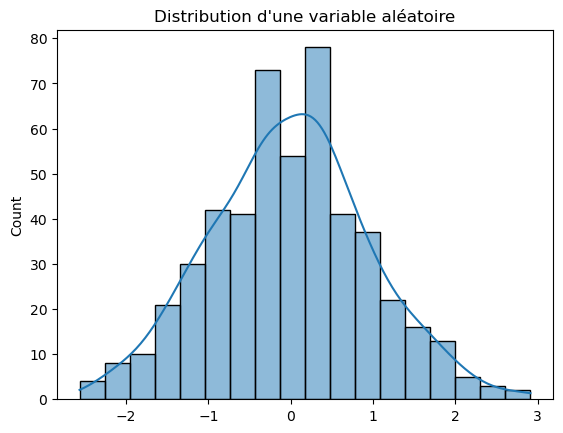

In [2]:
sns.histplot(x=y, kde=True)
plt.title("Distribution d'une variable aléatoire")
plt.show()

## II. Styles et contextes de figure

La fonction `sns.set_theme()` permet de définir globalement l'apparence des figures.

- `context` adapte notamment la taille des textes (`paper`, `notebook`, `talk`, `poster`) ;
- `style` contrôle le fond et la grille (`darkgrid`, `whitegrid`, `dark`, `white`, `ticks`).

In [3]:
my_colors = "Set2"
sns.color_palette(my_colors)

[(0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254)]

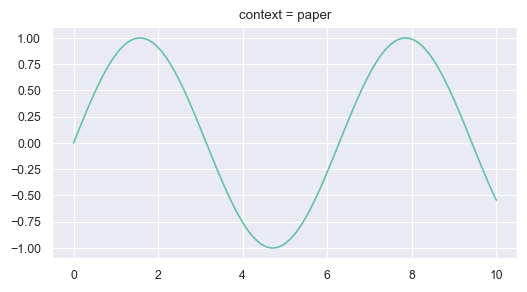

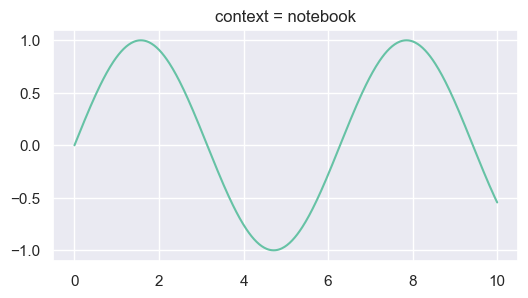

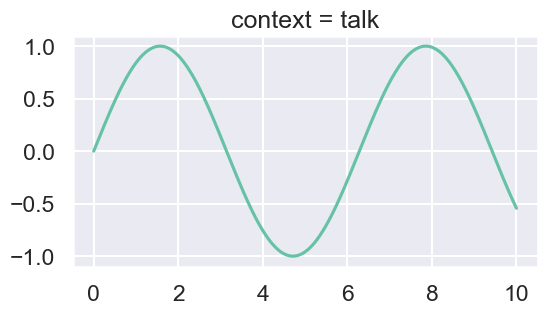

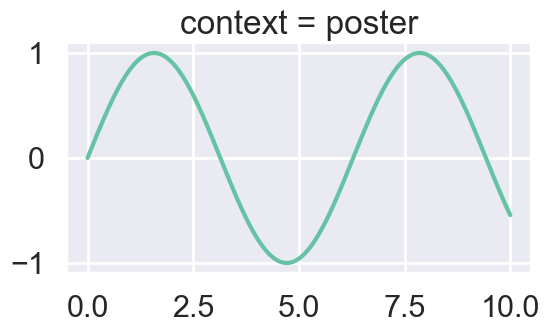

In [4]:
contexts = ["paper", "notebook", "talk", "poster"]

for c in contexts:
    sns.set_theme(context=c, palette=my_colors)
    plt.figure(figsize=(6, 3))
    sns.lineplot(x=x, y=np.sin(x))
    plt.title(f"context = {c}")
    plt.show()

<span style="color:blue">**QUESTION : Quelles différences observez-vous entre les différents contextes ?**</span>

<span style="color:red">**CORRECTION :** Le contenu ne change pas, mais les tailles de police, labels et graduations sont adaptées au contexte d'utilisation. `poster` est nettement plus grand que `paper`.</span>

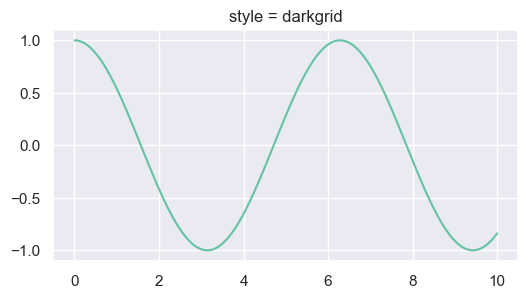

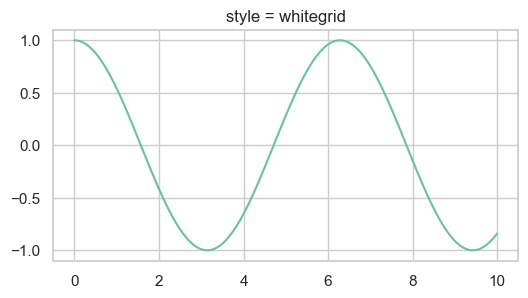

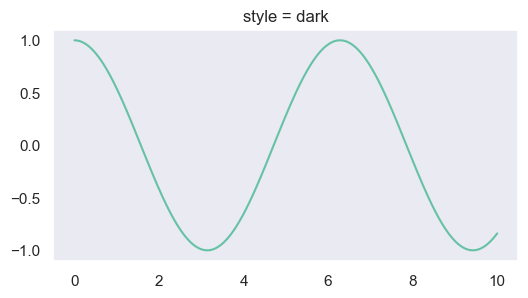

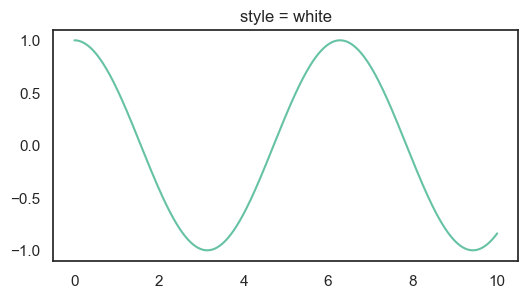

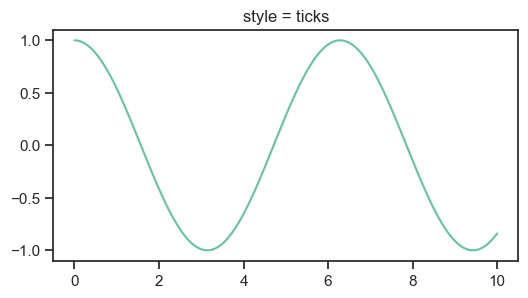

In [5]:
styles = ["darkgrid", "whitegrid", "dark", "white", "ticks"]

for s in styles:
    sns.set_theme(context="notebook", style=s, palette=my_colors)
    plt.figure(figsize=(6, 3))
    sns.lineplot(x=x, y=np.cos(x))
    plt.title(f"style = {s}")
    plt.show()

<span style="color:blue">**QUESTION : À quoi sert `sns.set_theme()` dans un script contenant plusieurs figures ?**</span>

<span style="color:red">**CORRECTION :** Il permet de fixer une apparence cohérente une seule fois au début du script.</span>

## III. Structure des données acceptées par Seaborn

Seaborn fonctionne particulièrement bien avec des données au format **long** :
chaque ligne correspond à une observation et chaque colonne à une variable.

Le format long est très pratique pour utiliser des variables catégorielles avec `hue`, `row` ou `col`.

<span style="color:blue">**QUESTION : Pourquoi le format long est-il particulièrement pratique avec Seaborn ?**</span>

<span style="color:red">**CORRECTION :** Parce qu'une colonne catégorielle peut être utilisée directement pour différencier les observations avec `hue`, `row`, `col`, etc.</span>

## IV. Jeu de données : mobilité urbaine

Le fichier `mobilite_urbaine.csv` contient des trajets synthétiques.

Variables : `mode`, `moment`, `meteo`, `abonnement`, `age`, `distance_km`,
`duree_min`, `calories`, `satisfaction`, `annee`.

In [6]:
sns.set_theme(style="whitegrid", context="notebook")

mobilite = pd.read_csv("mobilite_urbaine.csv")
print(mobilite.shape)
mobilite.head()

(1200, 10)


,mode,moment,meteo,abonnement,age,distance_km,duree_min,calories,satisfaction,annee
0,Vélo,Midi,Nuageux,Abonné,50,7.06,24.0,215,4.4,2025
1,Marche,Midi,Pluie,Abonné,34,3.35,53.9,218,3.8,2025
2,Marche,Soir,Soleil,Abonné,26,2.88,39.9,177,4.1,2021
3,Vélo,Soir,Nuageux,Abonné,64,10.78,46.5,338,4.1,2022
4,Vélo,Matin,Nuageux,Abonné,38,7.46,22.6,252,4.5,2025


In [7]:
mobilite.describe(include='all')

,mode,moment,meteo,abonnement,age,distance_km,duree_min,calories,satisfaction,annee
count,1200,1200,1200,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
unique,3,3,3,2,NaN,NaN,NaN,NaN,NaN,NaN
top,Vélo,Soir,Soleil,Abonné,NaN,NaN,NaN,NaN,NaN,NaN
freq,509,485,689,812,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,38.562500,4.855875,27.891833,162.958333,4.322250,2023.905833
std,NaN,NaN,NaN,NaN,12.454398,2.920494,16.187332,89.763901,0.480804,1.651536
min,NaN,NaN,NaN,NaN,16.000000,0.300000,3.000000,10.000000,2.300000,2021.000000
25%,NaN,NaN,NaN,NaN,30.000000,2.560000,17.300000,96.750000,4.000000,2023.000000
50%,NaN,NaN,NaN,NaN,38.000000,4.185000,25.250000,148.000000,4.400000,2024.000000
75%,NaN,NaN,NaN,NaN,47.000000,6.830000,34.725000,218.000000,4.700000,2025.000000


### Pair plots

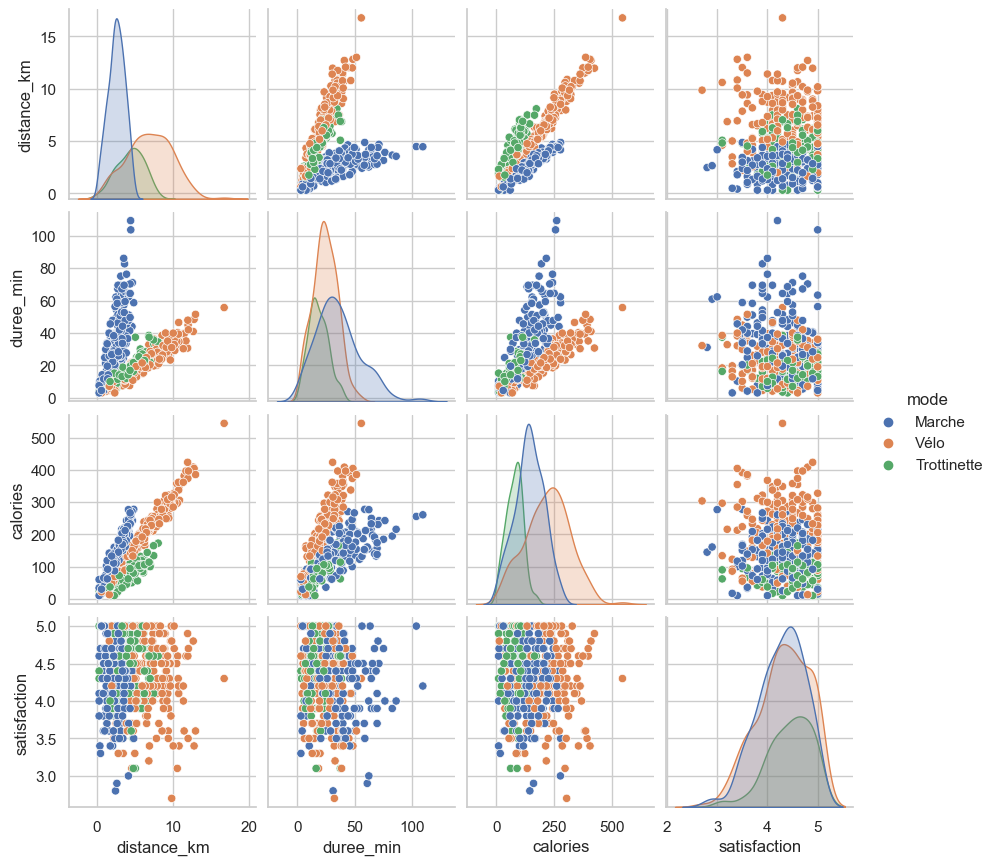

In [8]:
variables = mobilite[
    ["distance_km", "duree_min", "calories", "satisfaction", "mode"]
]

sns.pairplot(
    variables.sample(450, random_state=1),
    hue="mode",
    height=2.2
)
plt.show()

<span style="color:blue">**QUESTION : Pourquoi les graphes de la diagonale sont-ils différents des autres ? Que peut-on dire des relations entre distance, durée et calories ?**</span>

<span style="color:red">**CORRECTION :** La diagonale montre la distribution d'une variable seule. Les autres cases montrent des relations entre deux variables. Distance et durée sont positivement liées, et les calories augmentent globalement avec la distance.</span>

### Distributions jointes

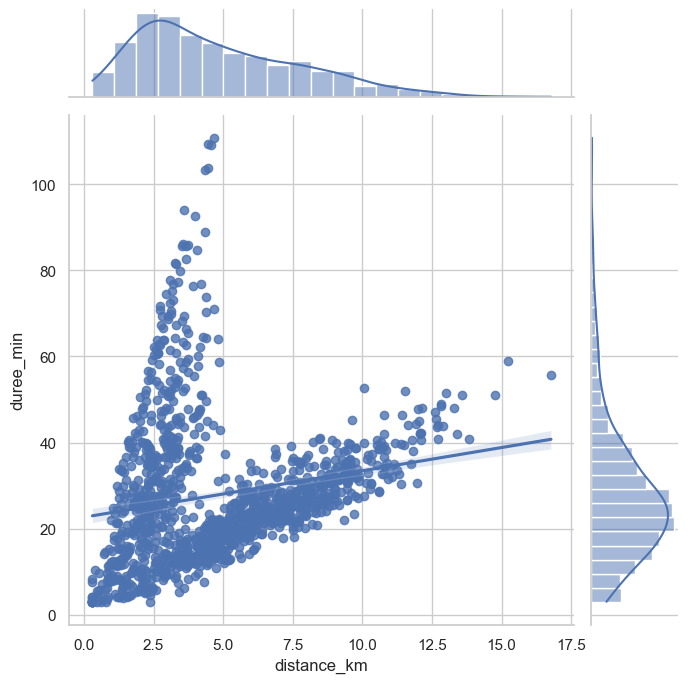

In [9]:
sns.jointplot(
    data=mobilite,
    x="distance_km",
    y="duree_min",
    kind="reg",
    height=7
)
plt.show()

<span style="color:blue">**QUESTION : Comment interpréter ce `jointplot` ?**</span>

<span style="color:red">**CORRECTION :** Le centre montre la relation entre distance et durée ; les marges montrent la distribution de chaque variable. La droite de régression met en évidence une relation positive.</span>

## V. Explorer plusieurs types de graphiques Seaborn

### KDE et densités

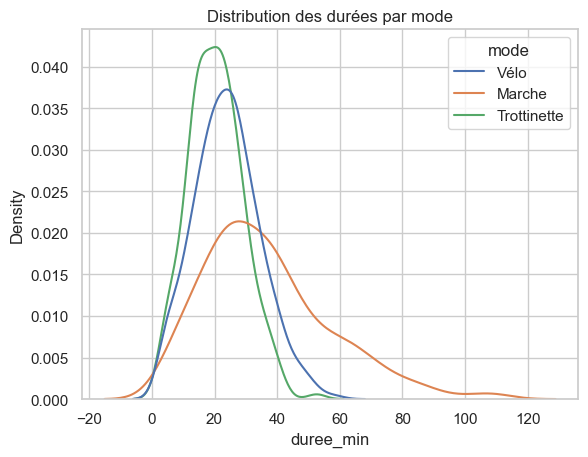

In [10]:
sns.kdeplot(
    data=mobilite,
    x="duree_min",
    hue="mode",
    fill=False,
    common_norm=False
)
plt.title("Distribution des durées par mode")
plt.show()

<span style="color:blue">**QUESTION : Quel intérêt présente une courbe KDE par rapport à un histogramme ?**</span>

<span style="color:red">**CORRECTION :** Elle donne une représentation lissée de la distribution et facilite souvent la comparaison de plusieurs groupes.</span>

### KDE bidimensionnelle

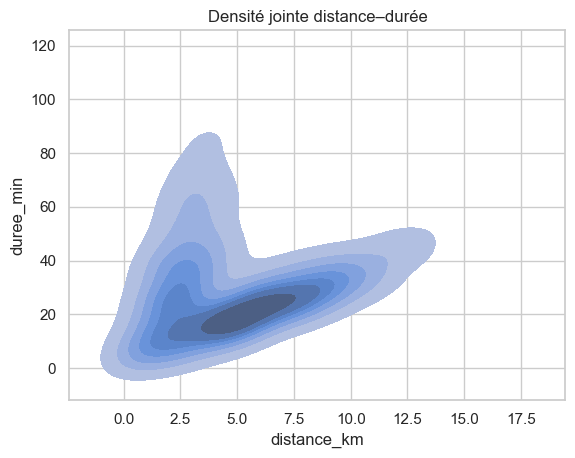

In [11]:
sns.kdeplot(
    data=mobilite,
    x="distance_km",
    y="duree_min",
    fill=True,
    levels=8,
    thresh=0.05
)
plt.title("Densité jointe distance–durée")
plt.show()

### `jointplot` avec histogramme hexagonal

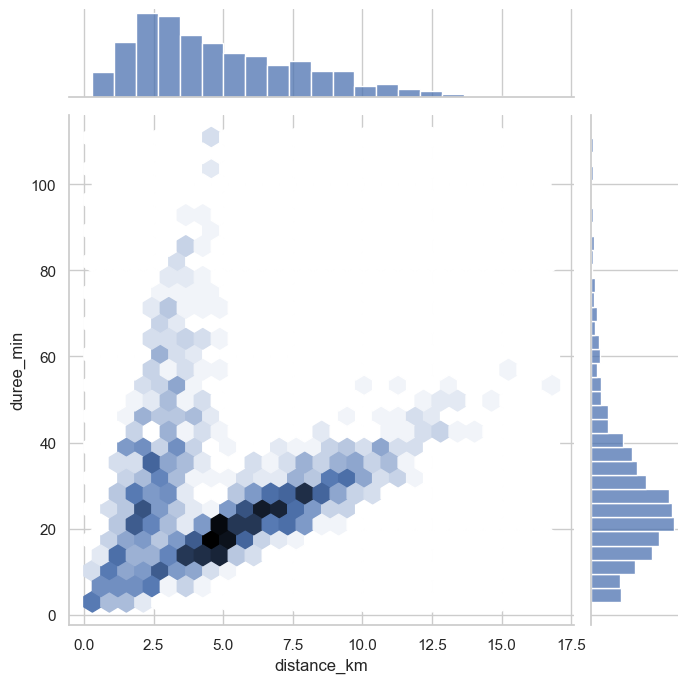

In [12]:
sns.jointplot(
    data=mobilite,
    x="distance_km",
    y="duree_min",
    kind="hex",
    height=7
)
plt.show()

<span style="color:blue">**QUESTION : Pourquoi un graphique hexagonal peut-il être utile lorsqu'il y a beaucoup de points ?**</span>

<span style="color:red">**CORRECTION :** Il agrège les observations par zones et représente leur densité, ce qui limite les problèmes de superposition.</span>

### Histogrammes facettés avec `FacetGrid`

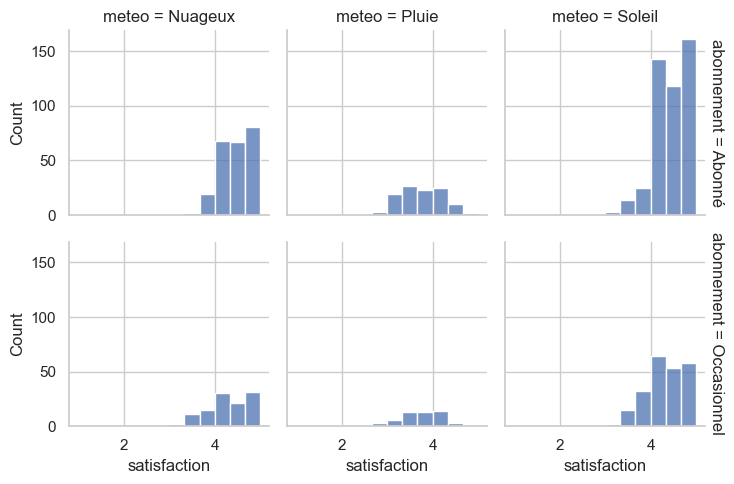

In [13]:
grid = sns.FacetGrid(
    mobilite,
    row="abonnement",
    col="meteo",
    margin_titles=True,
    height=2.5
)
grid.map_dataframe(
    sns.histplot,
    x="satisfaction",
    bins=np.linspace(1, 5, 13)
)
plt.show()

In [14]:
print("Effectifs par abonnement :")
print(mobilite.groupby("abonnement").size())

print("\nEffectifs par météo :")
print(mobilite.groupby("meteo").size())

Effectifs par abonnement :
abonnement
Abonné         812
Occasionnel    388
dtype: int64

Effectifs par météo :
meteo
Nuageux    348
Pluie      163
Soleil     689
dtype: int64


<span style="color:blue">**QUESTION : Les groupes n'ayant pas tous les mêmes effectifs, quelle représentation peut faciliter la comparaison des formes de distribution ?**</span>

<span style="color:red">**CORRECTION :** Une KDE est souvent plus adaptée car elle compare des distributions normalisées.</span>

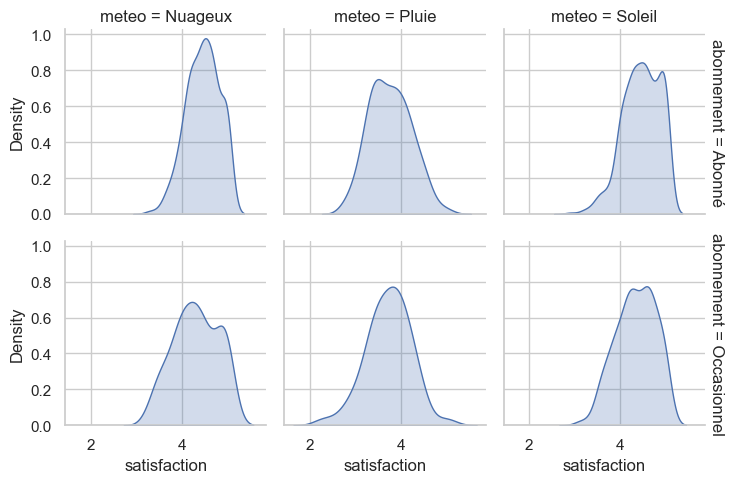

In [15]:
grid = sns.FacetGrid(
    mobilite,
    row="abonnement",
    col="meteo",
    margin_titles=True,
    height=2.5
)
grid.map_dataframe(sns.kdeplot, x="satisfaction", fill=True)
plt.show()

### Graphiques catégoriels

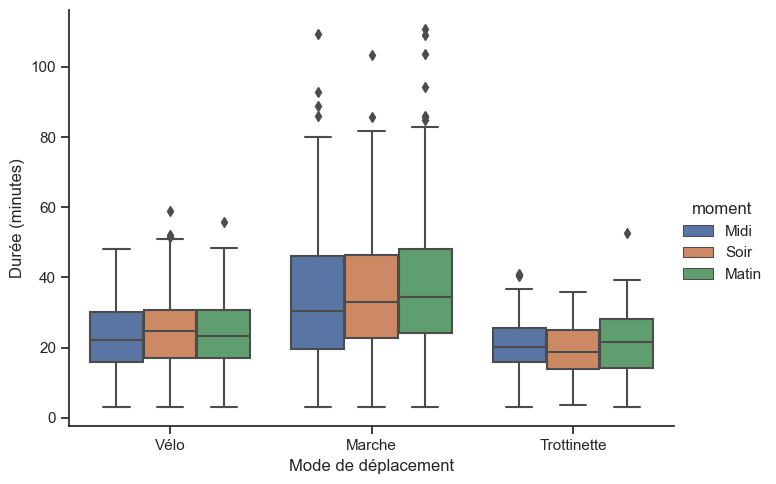

In [16]:
with sns.axes_style("ticks"):
    g = sns.catplot(
        data=mobilite,
        x="mode",
        y="duree_min",
        hue="moment",
        kind="box",
        height=5,
        aspect=1.4
    )
    g.set_axis_labels("Mode de déplacement", "Durée (minutes)")
plt.show()

<span style="color:blue">**QUESTION : Que permet de comparer ce boxplot ?**</span>

<span style="color:red">**CORRECTION :** Il compare la distribution des durées selon le mode et distingue les moments de la journée grâce à `hue`.</span>

### Graphiques de comptage

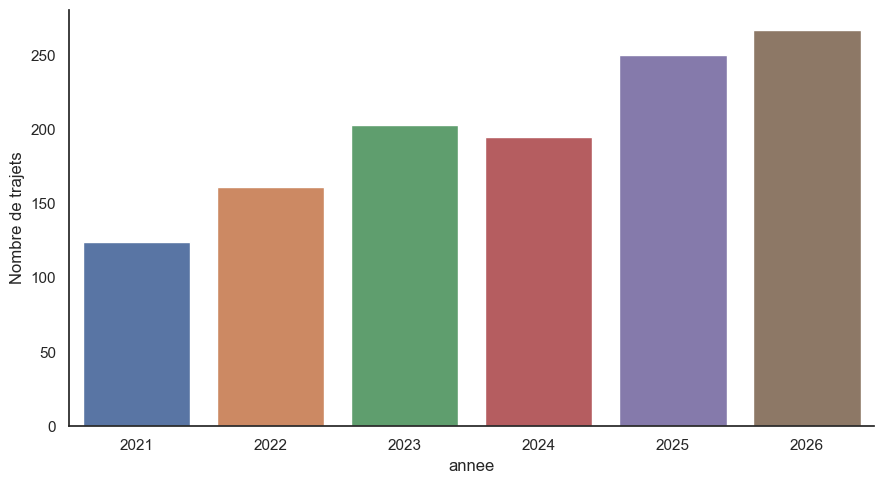

In [17]:
with sns.axes_style("white"):
    g = sns.catplot(
        data=mobilite,
        x="annee",
        kind="count",
        aspect=1.8
    )
    g.set_ylabels("Nombre de trajets")
plt.show()

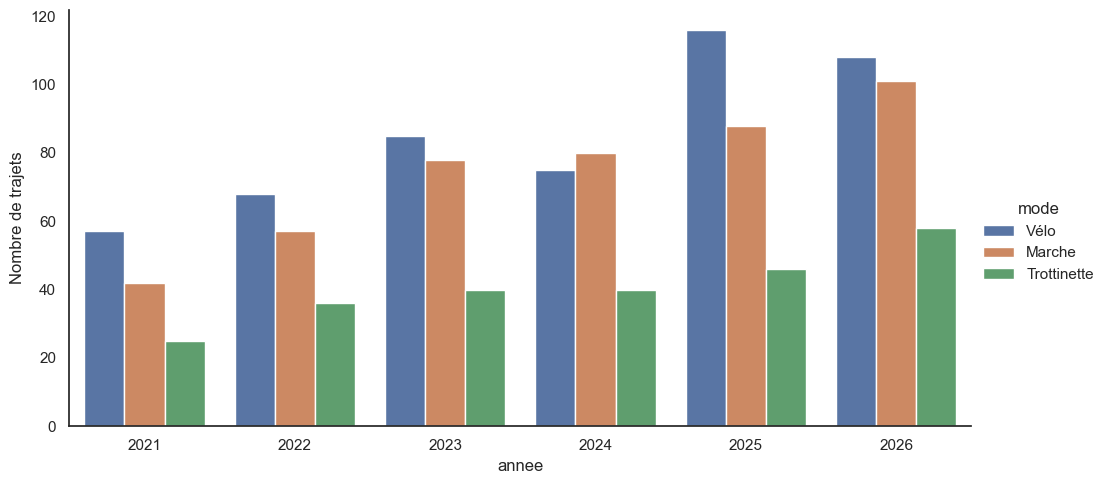

In [18]:
with sns.axes_style("white"):
    g = sns.catplot(
        data=mobilite,
        x="annee",
        hue="mode",
        kind="count",
        aspect=2.0
    )
    g.set_ylabels("Nombre de trajets")
plt.show()

<span style="color:blue">**QUESTION : Qu'apporte l'argument `hue='mode'` au second graphique ?**</span>

<span style="color:red">**CORRECTION :** Il décompose le nombre de trajets de chaque année selon le mode de déplacement.</span>

### Comparer des distributions selon une catégorie

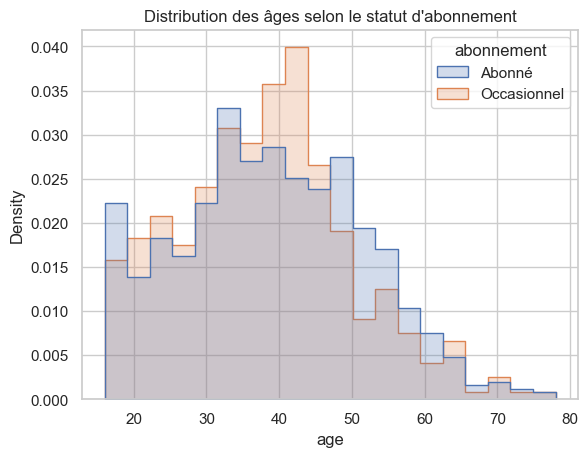

In [19]:
sns.histplot(
    data=mobilite,
    x="age",
    hue="abonnement",
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Distribution des âges selon le statut d'abonnement")
plt.show()

Un **violin plot** combine un résumé de distribution et une estimation de densité.

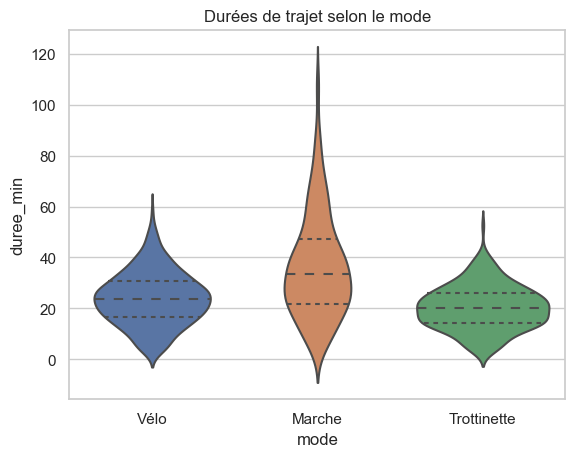

In [20]:
sns.violinplot(
    data=mobilite,
    x="mode",
    y="duree_min",
    inner="quartile"
)
plt.title("Durées de trajet selon le mode")
plt.show()

<span style="color:blue">**QUESTION : Quelle différence principale voyez-vous entre un boxplot et un violin plot ?**</span>

<span style="color:red">**CORRECTION :** Le boxplot résume surtout médiane et quartiles ; le violin plot ajoute la forme détaillée de la distribution.</span>

### Créer une catégorie numérique avec `pd.cut`

In [21]:
mobilite["classe_age"] = pd.cut(
    mobilite["age"],
    bins=[15, 25, 40, 55, 80],
    labels=["16-25", "26-40", "41-55", "56+"]
)

mobilite[["age", "classe_age"]].head()

,age,classe_age
0,50,41-55
1,34,26-40
2,26,26-40
3,64,56+
4,38,26-40


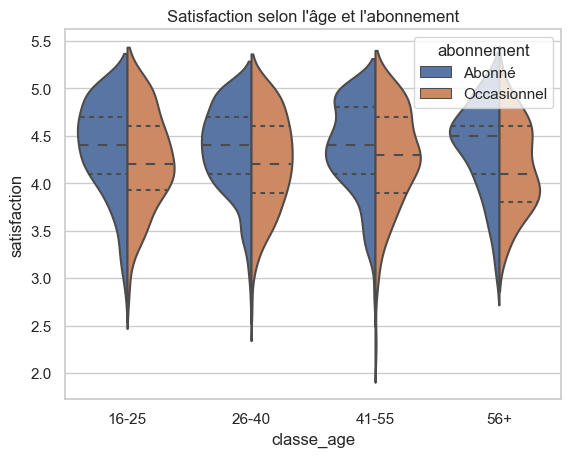

In [22]:
sns.violinplot(
    data=mobilite,
    x="classe_age",
    y="satisfaction",
    hue="abonnement",
    split=True,
    inner="quartile",
    order=["16-25", "26-40", "41-55", "56+"]
)
plt.title("Satisfaction selon l'âge et l'abonnement")
plt.show()

<span style="color:blue">**QUESTION : Quel est l'intérêt de `split=True` ici ?**</span>

<span style="color:red">**CORRECTION :** Avec deux catégories de `hue`, les deux distributions sont placées de part et d'autre du même violon.</span>

## VI. Exercice de synthèse

<span style="color:blue">**QUESTION : 1. Afficher un histogramme de `distance_km` avec une courbe KDE.**</span>

<span style="color:red">**CORRECTION :** `sns.histplot(..., kde=True)` combine les deux représentations.</span>

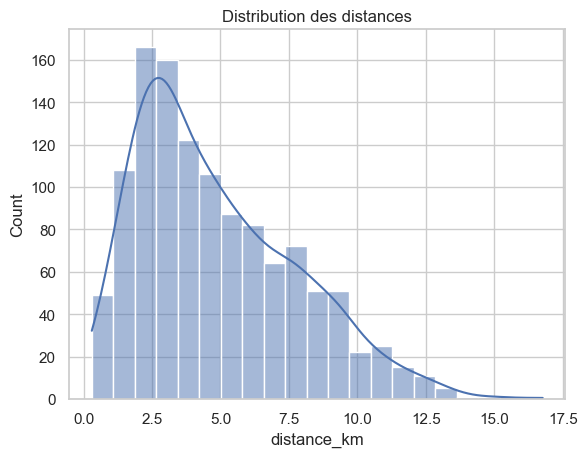

In [23]:
sns.histplot(data=mobilite, x="distance_km", kde=True)
plt.title("Distribution des distances")
plt.show()

<span style="color:blue">**QUESTION : 2. Comparer la distribution des distances selon le mode avec un boxplot.**</span>

<span style="color:red">**CORRECTION :** On utilise `mode` en abscisse et `distance_km` en ordonnée.</span>

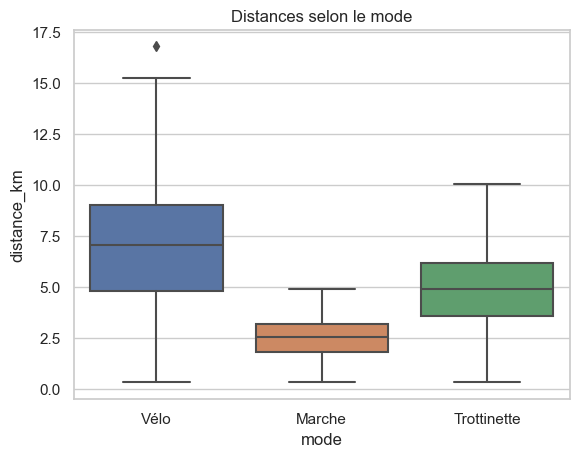

In [24]:
sns.boxplot(data=mobilite, x="mode", y="distance_km")
plt.title("Distances selon le mode")
plt.show()

<span style="color:blue">**QUESTION : 3. Représenter la relation entre distance et calories, avec une couleur différente selon le mode.**</span>

<span style="color:red">**CORRECTION :** `sns.scatterplot` permet d'utiliser `hue` pour distinguer les catégories.</span>

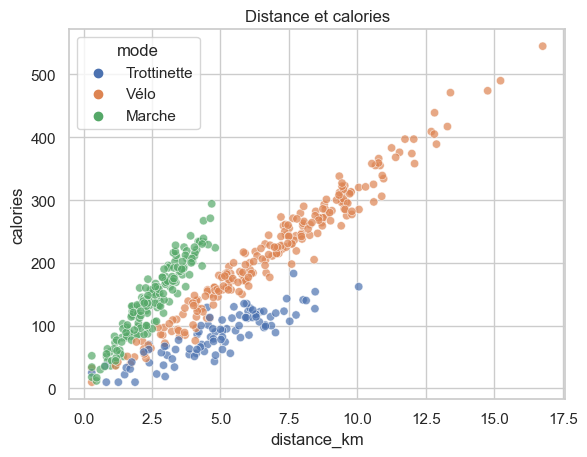

In [25]:
sns.scatterplot(
    data=mobilite.sample(500, random_state=2),
    x="distance_km",
    y="calories",
    hue="mode",
    alpha=0.7
)
plt.title("Distance et calories")
plt.show()

<span style="color:blue">**QUESTION : 4. Créer des histogrammes de durée séparés selon la météo avec `FacetGrid`.**</span>

<span style="color:red">**CORRECTION :** La variable `meteo` est placée en colonnes de la grille.</span>

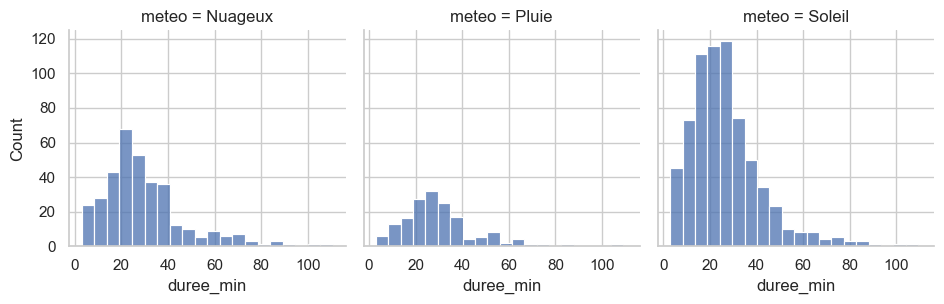

In [26]:
grid = sns.FacetGrid(mobilite, col="meteo", height=3.2)
grid.map_dataframe(sns.histplot, x="duree_min", bins=20)
plt.show()

<span style="color:blue">**QUESTION : 5. Afficher la satisfaction selon le mode et distinguer abonnés et occasionnels avec un violin plot.**</span>

<span style="color:red">**CORRECTION :** On utilise `mode`, `satisfaction` et `abonnement` comme `hue`.</span>

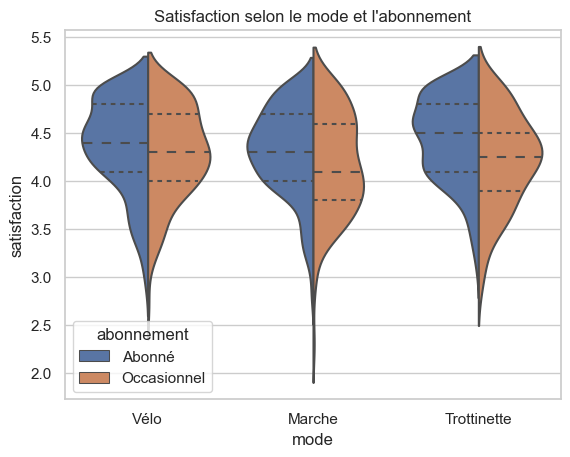

In [27]:
sns.violinplot(
    data=mobilite,
    x="mode",
    y="satisfaction",
    hue="abonnement",
    split=True,
    inner="quartile"
)
plt.title("Satisfaction selon le mode et l'abonnement")
plt.show()

## À retenir

Seaborn fournit des fonctions de haut niveau utiles pour l'exploration statistique :

- `histplot` et `kdeplot` pour les distributions ;
- `pairplot` pour explorer plusieurs variables numériques ;
- `jointplot` pour combiner relation bivariée et distributions marginales ;
- `FacetGrid` pour séparer les graphiques par sous-groupes ;
- `catplot`, `boxplot` et `violinplot` pour comparer des catégories ;
- `hue`, `row` et `col` pour représenter plusieurs dimensions d'un même jeu de données.